# Analiza eksploracyjna cech
Nieniejszy notatnik zawiera analizę eksploracyjną cech wyekstrahowanych z sygnałów polisomnograficznych pacjentów. Zostało utworzone 296 nowych atrybutów, co w połączeniu ze zmiennymi znajdującymi się w demographics.csv daje 305 cech opisujących. Wynikiem analizy będzie wyselekcjonowany zestaw cech, który posłuży do nauki modelu uczenia maszynowego do przewidywania wystąpienia u pacjenta zaburzeń poznawczych. Odpowiednie atrybuty zostaną wybrane w następujących krokach:
- odrzucenie cech o słabej jakości - o niskiej wariancji, wybrakowanych lub z wynikami mocno odbiegającymi od zakresu biologicznego;
- odrzucenie cech redundantnych na podstawie analizy korelacji;
## 0. Wczytanie i podgląd cech

In [1]:
import pandas as pd
import numpy as np

PATH = "/home/emil/studia/inzynierka/data/gold/features.parquet"
df = pd.read_parquet(PATH)

print("Wymiary:", df.shape)
print("\nTypy kolumn:")
print(df.dtypes.value_counts())
print("\nDuplikaty wierszy:", df.duplicated().sum())
print("Duplikaty pacjent-sesja:", df.duplicated(subset=["BDSPPatientID", "SessionID"]).sum())

Wymiary: (580, 310)

Typy kolumn:
float64    286
int64       16
object       7
bool         1
Name: count, dtype: int64

Duplikaty wierszy: 0
Duplikaty pacjent-sesja: 0


Dane wczytały się poprawnie, ilość wierszy i kolumn się zgadza. Nie ma zduplikowanych wierszy i każdemu pacjentowi przypisane jest jedno badanie, co zgdza się z założeniami zbioru.

In [2]:
import json

with open("/home/emil/studia/inzynierka/references/split.json") as f:
    split = json.load(f)

ids_train = split["splits"]["train"]
ids_val = split["splits"]["val"]
ids_test = split["splits"]["test"]

assert set(ids_train).isdisjoint(ids_val)
assert set(ids_train).isdisjoint(ids_test)
assert set(ids_val).isdisjoint(ids_test)

train = df[df["BidsFolder"].isin(ids_train)].copy()
val = df[df["BidsFolder"].isin(ids_val)].copy()
test = df[df["BidsFolder"].isin(ids_test)].copy()

print("Wymiary:", train.shape[0], val.shape[0], test.shape[0])

Wymiary: 412 84 84


## 1. Analiza jakości cech
Sekcja ma na celu wykrycie i odrzucenie cech, które nie wnoszą wiarygodnej informacji - o znikomej wariancji lub z nadmiarem brakujących wartości. Cechy takie nie zwiększają zdolności predykcyjnej modelu, a mogą zaburzać kolejne etapy selekcji, dlatego usuwa się je w pierwszej kolejności. Analizę przeprowadza się na zbiorze uczącym, aby uniknąć wycieku informacji ze zbiorów walidacyjnego i testowego.

In [3]:
num = train.select_dtypes(include=[np.number])

summary = pd.DataFrame({
    "n": num.count(),
    "n_braki": num.isna().sum(),
    "pct_braki": (num.isna().mean() * 100).round(2),
    "n_unikalne": num.nunique(),
    "srednia": num.mean(),
    "std": num.std(),
    "min": num.min(),
    "mediana": num.median(),
    "max": num.max(),
    "skosnosc": num.skew(),
})

In [4]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Cechy z brakami:")
display(summary[summary["pct_braki"] > 0].sort_values("pct_braki", ascending=False))

print("Cechy stale:")
display(summary[summary["n_unikalne"] <= 1])

print("Cechy o silnej skosnosci (|skew| > 3):")
display(summary[summary["skosnosc"].abs() > 3].sort_values("skosnosc", key=abs, ascending=False))

Cechy z brakami:


,n,n_braki,pct_braki,n_unikalne,srednia,std,min,mediana,max,skosnosc
Time_to_Event,206,206,50.000,193,"1,732.752",412.743,"1,098.000","1,683.000","2,555.000",0.240
BMI,257,155,37.620,238,29.810,6.877,18.110,28.410,71.540,1.649
hjorth_activity_frontal_N3,378,34,8.250,378,651.983,"1,585.155",40.735,336.664,"23,619.641",9.812
hjorth_complexity_frontal_N3,378,34,8.250,378,7.603,2.977,1.013,7.436,26.579,0.941
hjorth_mobility_frontal_N3,378,34,8.250,378,0.188,0.258,0.034,0.111,1.597,4.055
kurtosis_frontal_N3,378,34,8.250,378,3.847,0.757,1.578,3.775,12.750,4.414
line_length_frontal_N3,378,34,8.250,378,"31,362.591","112,414.590","3,689.935","9,425.116","1,323,646.955",7.556
sigma_kurtosis_frontal_N3,378,34,8.250,378,5.109,5.992,1.821,4.195,94.546,11.825
delta_kurtosis_frontal_N3,378,34,8.250,378,4.190,0.851,3.118,4.067,13.024,4.951
theta_kurtosis_frontal_N3,378,34,8.250,378,4.112,4.687,3.003,3.538,70.995,11.016


Cechy stale:


,n,n_braki,pct_braki,n_unikalne,srednia,std,min,mediana,max,skosnosc


Cechy o silnej skosnosci (|skew| > 3):


,n,n_braki,pct_braki,n_unikalne,srednia,std,min,mediana,max,skosnosc
theta_kurtosis_central_N3,378,34,8.250,378,3.783,2.884,3.037,3.509,58.340,18.121
slowing_index_occipital_N3,378,34,8.250,378,0.046,0.117,0.006,0.034,2.213,17.191
beta_rel_power_frontal_N3,378,34,8.250,378,0.009,0.037,0.001,0.005,0.700,17.120
alpha_kurtosis_frontal_REM,397,15,3.640,397,4.556,4.800,2.467,3.988,94.071,16.844
slowing_index_frontal_N3,378,34,8.250,378,0.052,0.136,0.005,0.035,2.556,16.714
beta_rel_power_occipital_N3,378,34,8.250,378,0.011,0.037,0.001,0.006,0.670,15.651
theta_kurtosis_frontal_N1,412,0,0.000,412,4.622,4.575,2.879,4.012,87.327,15.189
hjorth_activity_central_N2,412,0,0.000,412,346.485,"1,406.179",19.612,136.317,"25,299.906",14.381
theta_kurtosis_frontal_REM,397,15,3.640,397,4.645,5.676,2.881,3.906,102.748,14.139
theta_kurtosis_frontal_N2,412,0,0.000,412,4.438,4.187,3.210,3.895,76.846,13.960


Jedyną cechą zawierającą poważne braki jest BMI, co zostało już zbadane na podstawie poprzedniej analizy i na tym etapie zostaje definitywnie odrzucona. Pozostałe braki występują w cechach z kanałów eeg liczonych dla każdej fazy osobno. Można zauważyć, że braki występują wyłącznie dla kanałów REM i N3, co oznacza, że niektórzy pacjenci w ogóle nie byli w tej fazie snu podczas badania. Ze względu na to nie należy traktować tego jako braki, a jako cenną informację mówiącą o braku występowania konkretnej fazy snu. Wiele cech zawiera dużą skośność, przeważnie dodatnią, oznacza to występowanie wartości dstających, które mogą wprowadzić szum do modelu. Jest to istotna informacja, która zostanie wzięta pod uwagę podczas budowy modeli.

## 2. Analiza eksploracyjna cech

### 2.1 Analiza cech klinicznych
Cechy kliniczne zostały wydzielone do osobnej analizy ze względu na łatwość ich interpretacji oraz niewielką liczbę, która pozwala przyjrzeć się każdej z nich osobno - jej rozkładowi, separacji klas i wzajemnym korelacjom. Blok cech EEG, znacznie liczniejszy, nie poddaje się analizie po jednej cesze i został potraktowany zbiorczo w podpunkcie 2.2.

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

macro = ["TST", "TRT", "SPT", "SE", "SME", "SL", "REM_latency", "WASO",
         "N1_time", "N2_time", "N3_time", "REM_time",
         "N1_pct", "N2_pct", "N3_pct", "REM_pct", "NA", "N1_transitions", "SFI"]
event = ["AHI", "PLMS", "PLMSI"]
oxi = ["mean_SpO2", "minimal_SpO2", "ODI", "sub90_SpO2"]
non_eeg = macro + event + oxi
target = "Cognitive_Impairment"

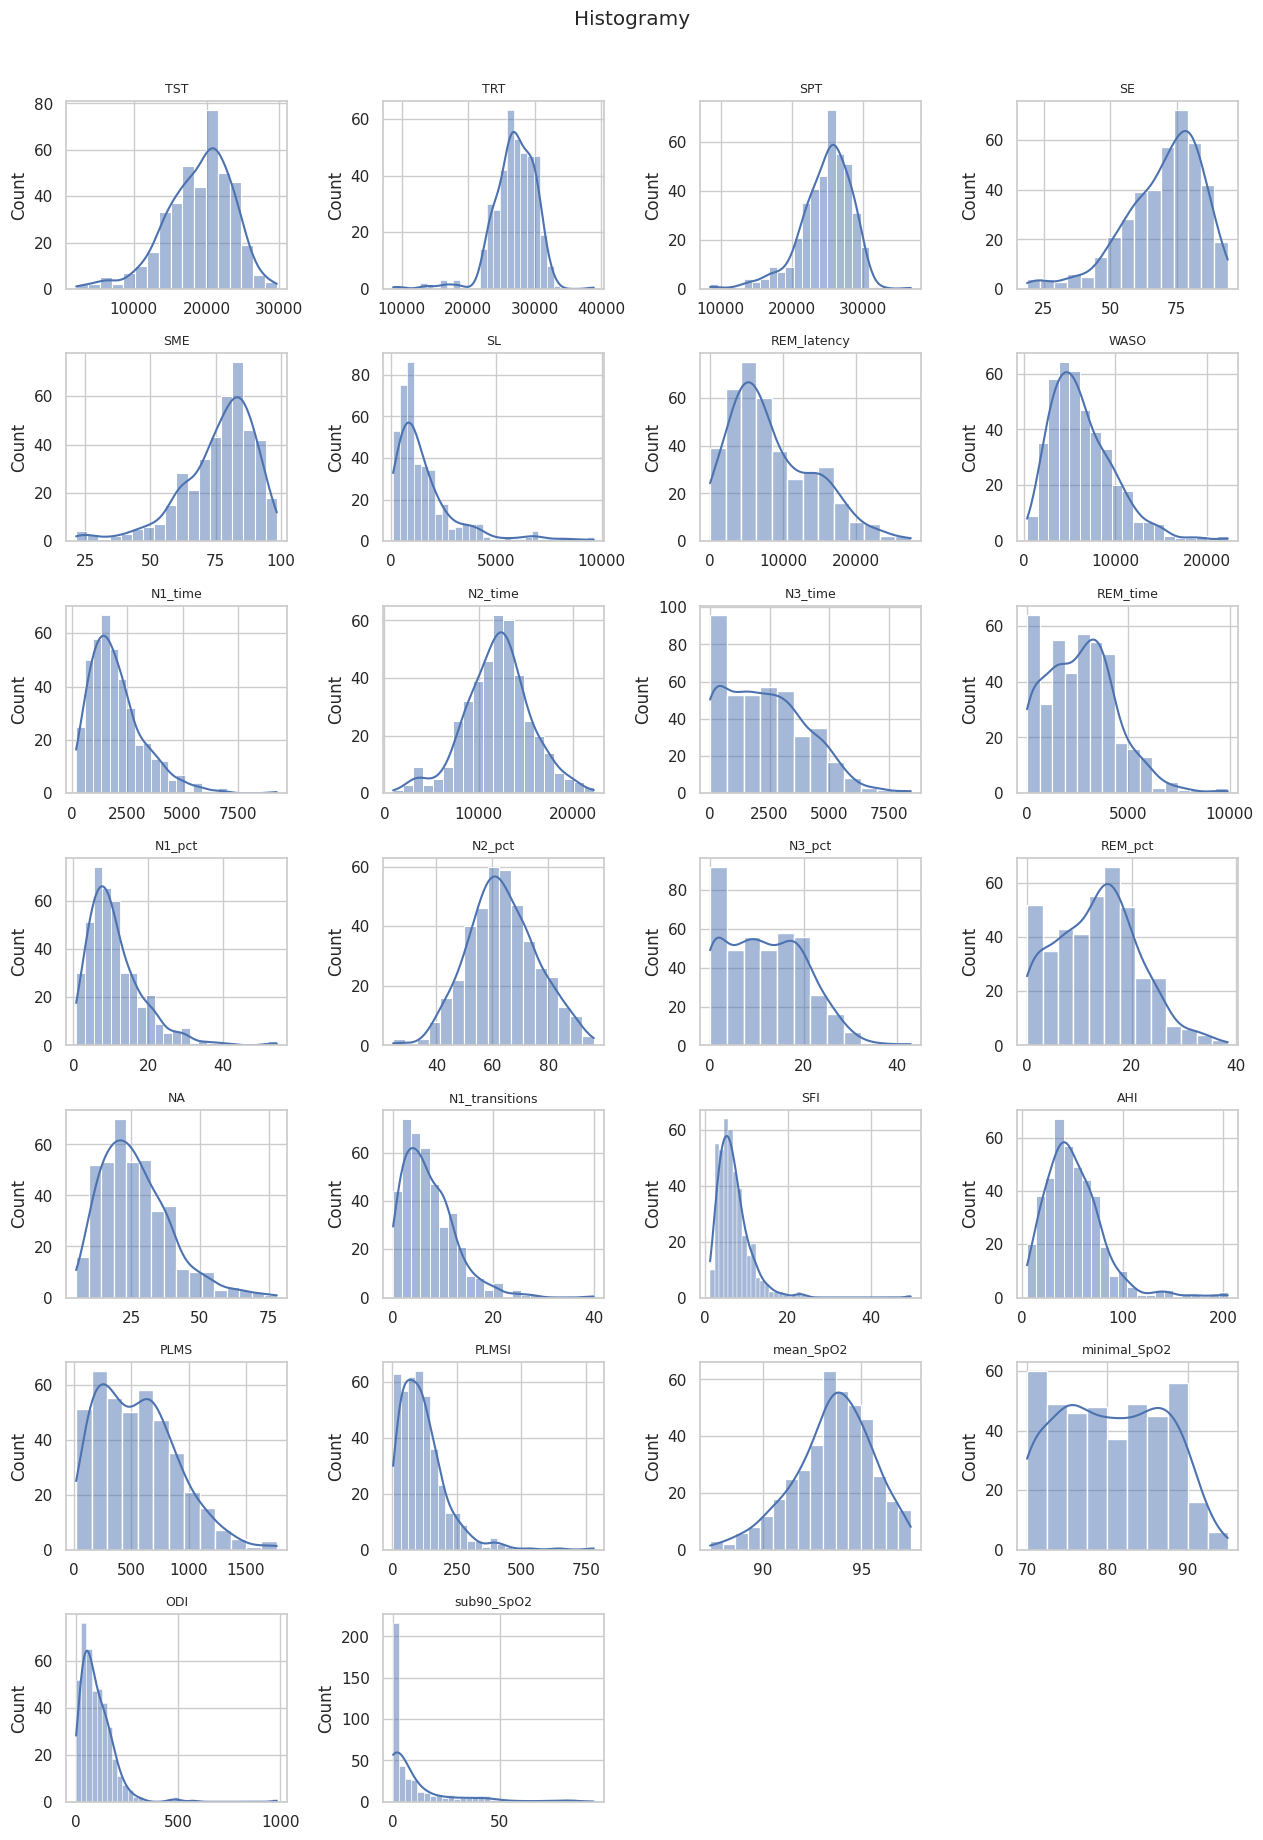

In [6]:
def siatka(data, cols, ncols=4, rozmiar=(3.2, 2.6)):
    n = len(cols)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * rozmiar[0], nrows * rozmiar[1]))
    return fig, np.array(axes).reshape(-1)

fig, axes = siatka(train, non_eeg)
for ax, c in zip(axes, non_eeg):
    sns.histplot(train[c].dropna(), kde=True, ax=ax, color="#4C72B0")
    ax.set_title(c, fontsize=9)
    ax.set_xlabel("")
for ax in axes[len(non_eeg):]:
    ax.set_visible(False)
fig.suptitle("Histogramy", y=1.01)
fig.tight_layout()
plt.show()

Rozkłady zmiennych klinicznych są skośne w obie strony - lewoskośne: TST, TRT, SPT, SE, SME, mean_SpO2 oraz prawoskośne: SL, REM_latency, WASO, N1_time, N1_pct, N1_transitions, AHi, PLMSI, ODI, sub90_SpO2. Część rozkładów nie jest przy tym gładka, lecz zawiera skupisko wartości na zerze - dotyczy to N3_time, N3_pct, REM_time i REM_pct i odpowiada pacjentom, którzy nie weszli w dane stadium snu; to ta sama grupa, która w cechach EEG zawiera braki, z tą różnicą, że tutaj nieobecność stadium zapisana jest jako zero. Na histogramie AHI i ODI można zobaczyć, że większość wartości odbiega od norm anatomicznych - AHI praktycznie nie spada poniżej 5, a niektóre wartości sięgają 200, gdzie 30 jest uważane za stan ciężki. ODI również ma wiele wartości poza biologicznym zakresem.

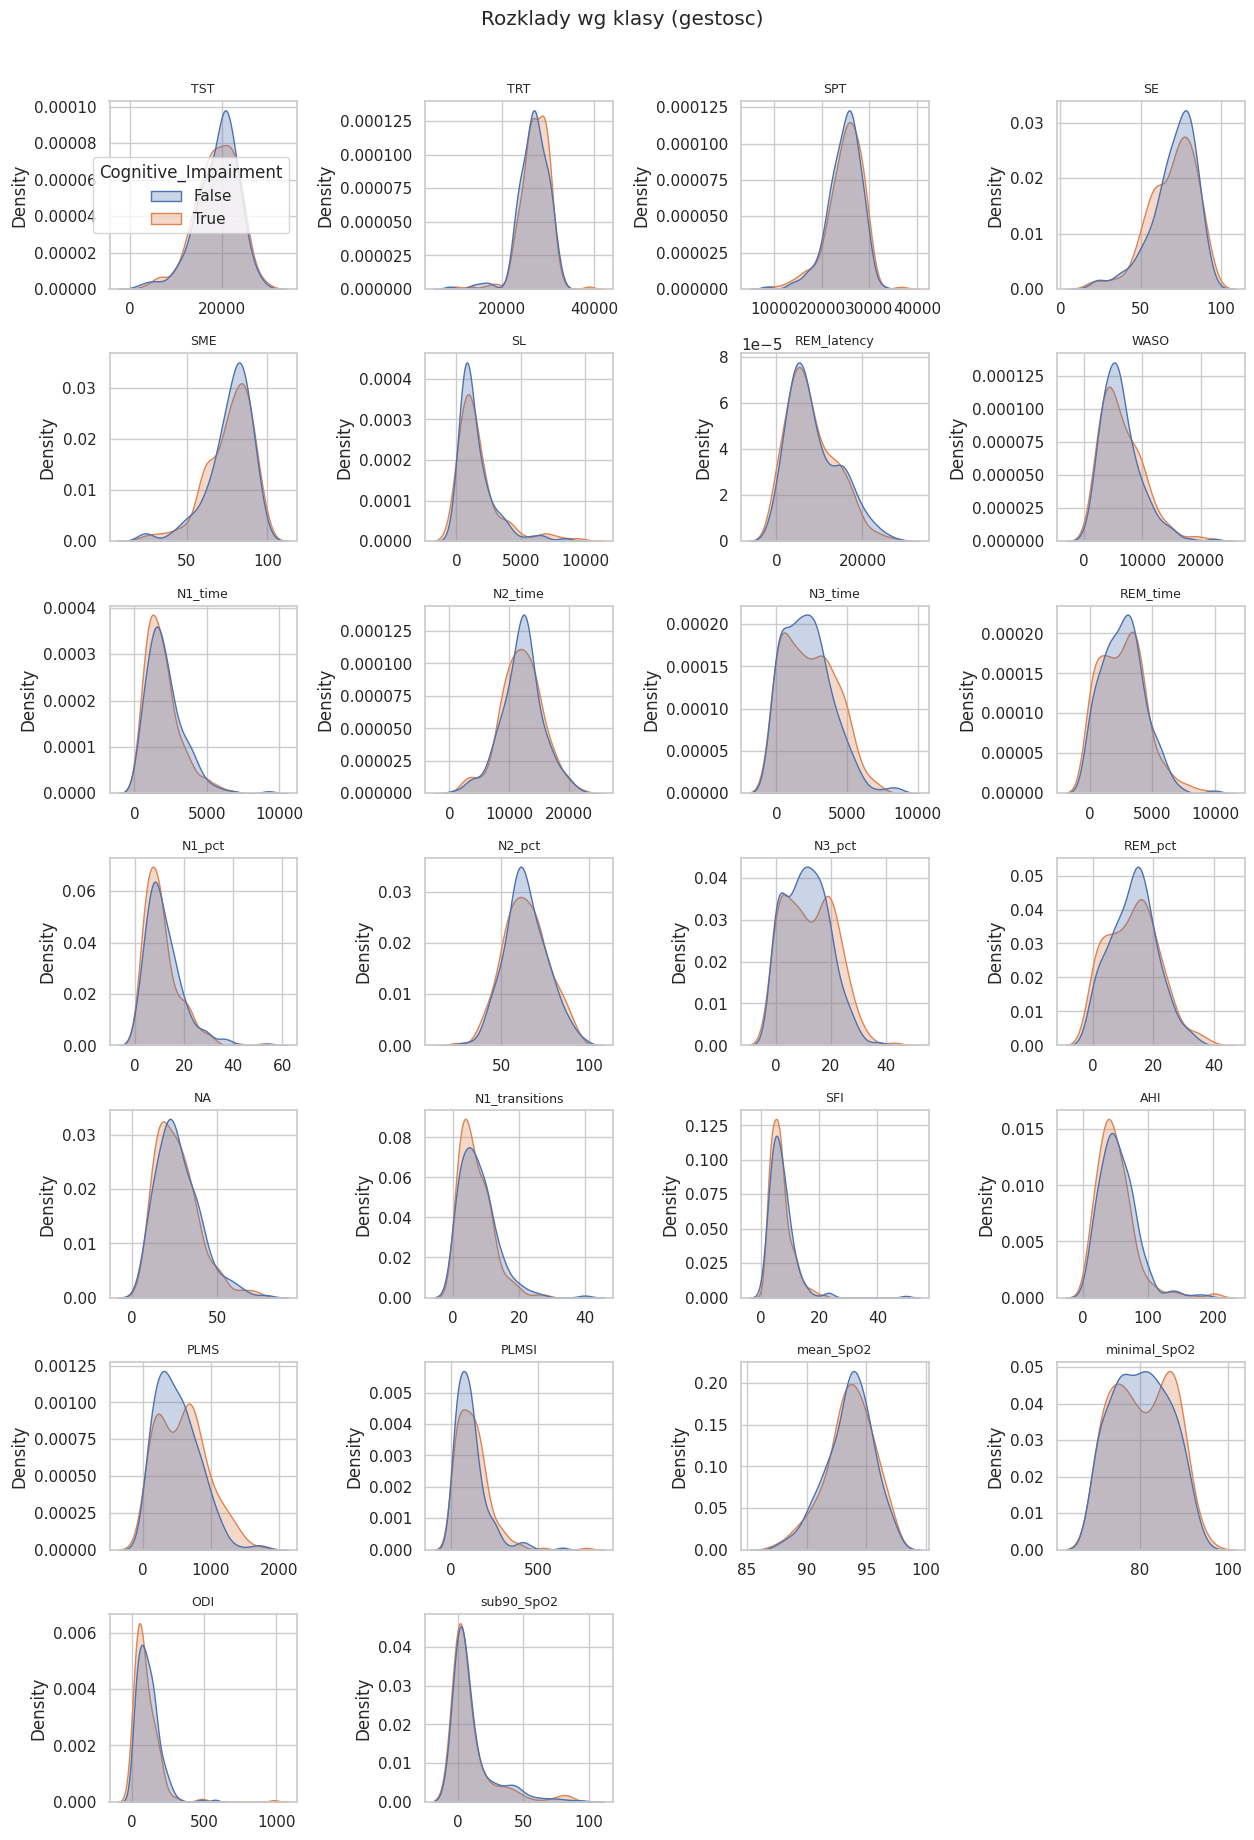

In [7]:
fig, axes = siatka(train, non_eeg)
for i, (ax, c) in enumerate(zip(axes, non_eeg)):
    sns.kdeplot(data=train, x=c, hue=target, common_norm=False,
                fill=True, alpha=0.3, ax=ax, legend=(i == 0))
    ax.set_title(c, fontsize=9)
    ax.set_xlabel("")
for ax in axes[len(non_eeg):]:
    ax.set_visible(False)
fig.suptitle("Rozklady wg klasy (gestosc)", y=1.01)
fig.tight_layout()
plt.show()

Histogramy w większości nachodzą na siebie - żadna z cech nie separuje dobrze zmiennej opisywanej. Znikome ale widoczne przesunięcie mają PLMS i PLMI w stronę trochę wyższych wartości dla chorych.

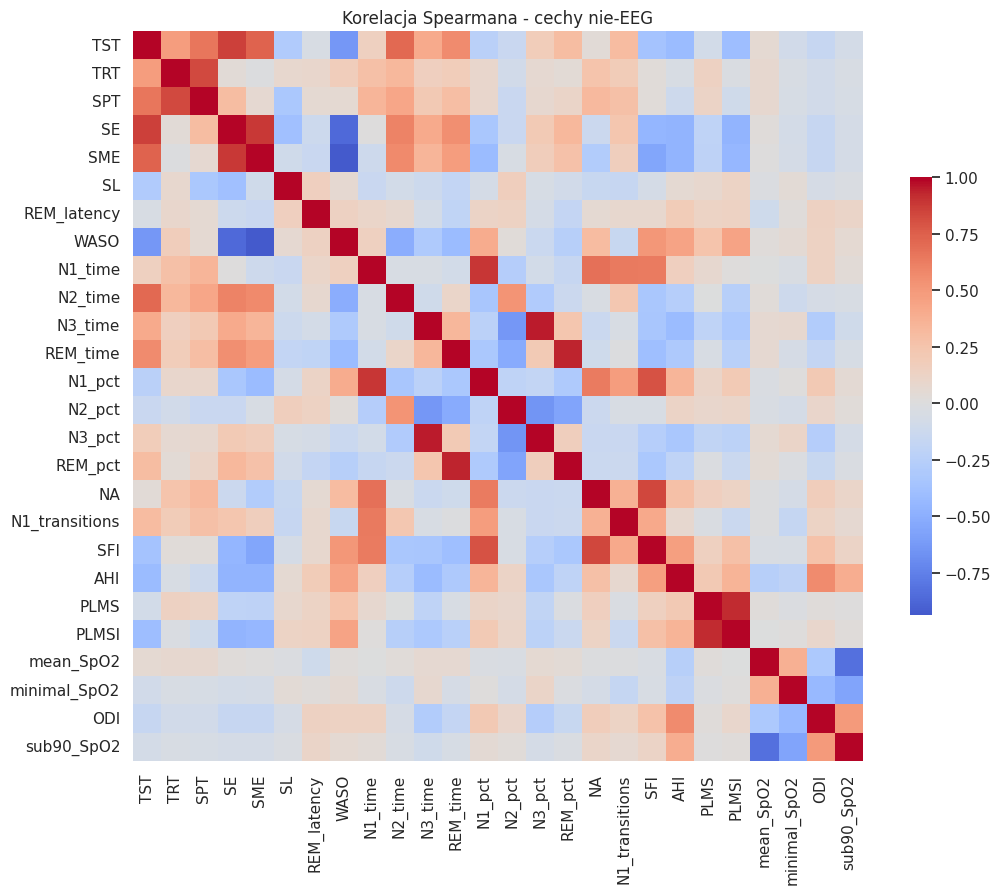

In [8]:
corr = train[non_eeg].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.6}, xticklabels=True, yticklabels=True)
plt.title("Korelacja Spearmana - cechy nie-EEG")
plt.tight_layout()
plt.show()

Macierz korelacji ujawnia silną redundancję występującą między cechami. Najsilniejszą korelacją wykazują się pary opisujące czas i % danej fazy snu, równie silną korelację ma PLMS i PLMSI oraz grupa związana z czasem snu: TST, TRT, SPT, SE, SME, WASO. Oznacza to, że wiele z tych cech może zostać zredukowana.

In [9]:
import pandas as pd
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

y = train[target].astype(int)
wyniki = []
for c in non_eeg:
    x = train[c]
    maska = x.notna()
    auc = roc_auc_score(y[maska], x[maska])
    rho, p = spearmanr(x[maska], y[maska])
    wyniki.append({"cecha": c, "AUC": auc, "AUC_sila": abs(auc - 0.5),
                   "spearman_rho": rho, "p": p})

zwiazek = pd.DataFrame(wyniki).sort_values("AUC_sila", ascending=False).reset_index(drop=True)
display(zwiazek.round(3))

,cecha,AUC,AUC_sila,spearman_rho,p
0,ODI,0.417,0.083,-0.143,0.004
1,PLMS,0.562,0.062,0.107,0.030
2,AHI,0.441,0.059,-0.103,0.038
3,PLMSI,0.556,0.056,0.097,0.049
4,N1_pct,0.453,0.047,-0.081,0.101
5,N1_time,0.455,0.045,-0.079,0.112
6,N3_pct,0.541,0.041,0.071,0.147
7,N1_transitions,0.460,0.040,-0.069,0.162
8,N3_time,0.534,0.034,0.059,0.231
9,TRT,0.533,0.033,0.058,0.240


Analiza AUC i korelacji Spearmana potwierdza brak liniowej zależnośći między cechami klinicznymi a zmienną opisywaną.

## 2.2 Cechy eeg
W tym punkcie zostanie zbadane powiązanie cech eeg ze zmienną opisywaną.

In [10]:
stadia = {"W", "N1", "N2", "N3", "REM"}
eeg = [c for c in train.columns if c.rsplit("_", 1)[-1] in stadia]

y = train[target].astype(int)
wyniki_eeg = []
for c in eeg:
    x = train[c]
    maska = x.notna()
    auc = roc_auc_score(y[maska], x[maska])
    rho, p = spearmanr(x[maska], y[maska])
    wyniki_eeg.append({"cecha": c, "AUC": auc, "AUC_sila": abs(auc - 0.5),
                       "spearman_rho": rho, "p": p})

auc_eeg = pd.DataFrame(wyniki_eeg).sort_values("AUC_sila", ascending=False).reset_index(drop=True)
print(f"Cech EEG: {len(eeg)} | mediana |AUC-0,5|: {auc_eeg['AUC_sila'].median():.3f} | maks: {auc_eeg['AUC_sila'].max():.3f}")
display(auc_eeg.head(15).round(3))

Cech EEG: 270 | mediana |AUC-0,5|: 0.031 | maks: 0.151


,cecha,AUC,AUC_sila,spearman_rho,p
0,kurtosis_frontal_N2,0.349,0.151,-0.262,0.000
1,delta_kurtosis_frontal_N2,0.378,0.122,-0.212,0.000
2,kurtosis_central_N2,0.383,0.117,-0.203,0.000
3,kurtosis_occipital_W,0.396,0.104,-0.181,0.000
4,delta_kurtosis_central_N2,0.398,0.102,-0.177,0.000
5,delta_theta_ratio_frontal_N2,0.400,0.100,-0.174,0.000
6,theta_rel_power_frontal_N2,0.600,0.100,0.172,0.000
7,sigma_kurtosis_occipital_N2,0.406,0.094,-0.163,0.001
8,line_length_occipital_REM,0.589,0.089,0.153,0.002
9,alpha_kurtosis_central_N2,0.412,0.088,-0.152,0.002


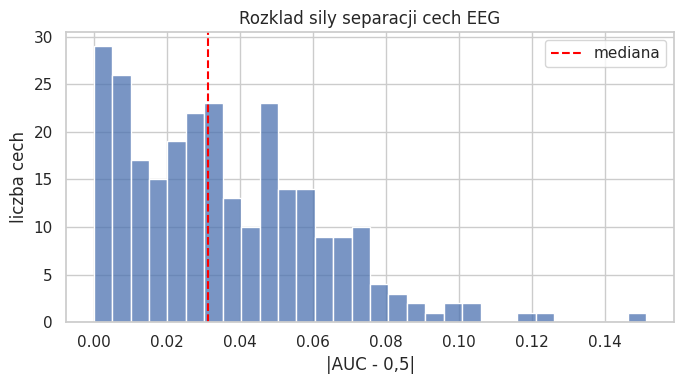

In [11]:
plt.figure(figsize=(7, 4))
sns.histplot(auc_eeg["AUC_sila"], bins=30, color="#4C72B0")
plt.axvline(auc_eeg["AUC_sila"].median(), color="red", linestyle="--", label="mediana")
plt.xlabel("|AUC - 0,5|")
plt.ylabel("liczba cech")
plt.title("Rozklad sily separacji cech EEG")
plt.legend()
plt.tight_layout()
plt.show()

Cechy eeg, podobnie jak klinicznie, mają słabą separację jednowymiawą - mediana |AUC - 0,5| wynosi zaledwie 0,031. Jest jednak istotna różnica, ponieważ pojedyncze cechy takie jak: kurtoza w fazie N2 (zarówno całościowa jak i w danych pasmach) oraz moce względne pasm theta i delta są w jakiś sposób skorelowane ze zmienną opisywaną. Pojedyncze cechy eeg nadal są słabe, ale i tak niosą za sobą więcej informacji niż cechy kliniczne.

### 2.3 Podsumowanie
Z analizy eksploracyjnej można wyciągnąć cztery wnioski. Po pierwsze, rozkłady cech klinicznych są skośne w obie strony i miejscami skupione na zerze (nieobecność stadiów N3 i REM), a histogramy AHI oraz ODI ujawniły wartości fizjologicznie niemożliwe dla indeksów liczonych na godzinę, co wskazuje na błąd skali tych cech - w obecnej postaci wymagają przeliczenia lub wykluczenia. Po drugie, żadna cecha nie rozgranicza klas samodzielnie - wartości AUC zarówno cech klinicznych, jak i EEG leżą blisko 0,5, co oznacza brak istotnej zależności jednowymiarowej, choć nie wyklucza sygnału wielowymiarowego. Po trzecie, najsilniejsze pojedyncze sygnały pochodzą jednak z EEG, nie z kliniki - skupiają się w stadium N2, w kurtozie sygnału i względnej mocy theta - co wskazuje, gdzie szukać informacji predykcyjnej. Po czwarte, zestaw cech jest silnie redundantny i może zostać zredukowany do kilku niezależnych wymiarów, co uzasadnia kolejny krok.

## 3. Analiza korelacji i redukcja redundancji
Cechy wyekstrahowane na region na fazę są z natury dość silnie skorelowane, a anliza eksploracyjna potwierdziła korelację cech klinicznych. W celu usunięcia redundancji zostanie przeprowadzona nienadzorowana redukcja. Korelację Spearmana między cechami została przeksztalcona 1 − |rho|, cechy grupuje się hierarchicznie, a z każdej grupy przekraczającej próg redundancji zostaje jeden reprezentant - cecha najsilniej skorelowana z resztą grupy. Analizę prowadzi się na zbiorze uczącym, a wyłonioną listę reprezentantów stosuje dalej jako stałą.

In [12]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

prog = 0.8

nie_cechy = ["SiteID", "BDSPPatientID", "CreationTime", "BidsFolder", "SessionID",
             "Race", "Ethnicity", "Last_Known_Visit_Date", "Time_to_Event",
             "Time_to_Last_Visit", "Cognitive_Impairment", "BMI", "ODI", "AHI"]
cechy = [c for c in train.select_dtypes(include=[np.number]).columns if c not in nie_cechy]

corr = train[cechy].corr(method="spearman").abs().fillna(0.0)
m = corr.to_numpy()
np.fill_diagonal(m, 1.0)
dist = 1.0 - m
np.fill_diagonal(dist, 0.0)
Z = linkage(squareform(dist, checks=False), method="complete")
klastry = pd.Series(fcluster(Z, t=1 - prog, criterion="distance"), index=cechy)

reprezentanci = []
for g, czlonkowie in klastry.groupby(klastry):
    cols = czlonkowie.index.tolist()
    reprezentanci.append(corr.loc[cols, cols].mean(axis=1).idxmax() if len(cols) > 1 else cols[0])

odrzucone = [c for c in cechy if c not in reprezentanci]
print(f"Cech przed: {len(cechy)} | po redukcji: {len(reprezentanci)} | odrzucono: {len(odrzucone)}")

Cech przed: 295 | po redukcji: 171 | odrzucono: 124


In [13]:
for g in sorted(klastry.unique()):
    cols = klastry[klastry == g].index.tolist()
    if len(cols) > 1:
        medoid = corr.loc[cols, cols].mean(axis=1).idxmax()
        print(f"[{len(cols)}] zostaje: {medoid}  | odrzucone: {[c for c in cols if c != medoid]}")

[2] zostaje: SME  | odrzucone: ['WASO']
[2] zostaje: TST  | odrzucone: ['SE']
[2] zostaje: REM_time  | odrzucone: ['REM_pct']
[2] zostaje: TRT  | odrzucone: ['SPT']
[2] zostaje: mean_SpO2  | odrzucone: ['sub90_SpO2']
[2] zostaje: theta_alpha_ratio_frontal_N3  | odrzucone: ['theta_alpha_ratio_central_N3']
[2] zostaje: theta_alpha_ratio_frontal_N2  | odrzucone: ['theta_alpha_ratio_central_N2']
[2] zostaje: theta_alpha_ratio_frontal_REM  | odrzucone: ['theta_alpha_ratio_central_REM']
[2] zostaje: theta_alpha_ratio_frontal_N1  | odrzucone: ['theta_alpha_ratio_central_N1']
[2] zostaje: theta_alpha_ratio_frontal_W  | odrzucone: ['theta_alpha_ratio_central_W']
[2] zostaje: N3_time  | odrzucone: ['N3_pct']
[2] zostaje: kurtosis_frontal_N3  | odrzucone: ['kurtosis_central_N3']
[4] zostaje: line_length_occipital_N2  | odrzucone: ['line_length_occipital_N1', 'line_length_occipital_N3', 'line_length_occipital_REM']
[4] zostaje: line_length_frontal_N2  | odrzucone: ['line_length_frontal_N1', 'line_

Porównano podział przy |rho| = 0,8 i 0,85 - przy obu sklejane cechy okazały się merytorycznie spójne: łączyły się sąsiednie regiony (czołowy z centralnym), ta sama miara w skorelowanych stadiach oraz pokrewne miary widmowe aktywności wolnofalowej (moc delty, wskaźnik spowolnienia, stosunek delta/alfa). Wybrano próg 0,8, ponieważ dawał wyraźniejszą redukcję, a powstałe grupy wciąż odpowiadały temu samemu zjawisku. Krok przeprowadzono na zbiorze uczącym i nie korzysta on ze zmiennej opisywanej, więc nie grozi wyciekiem informacji do zbiorów walidacyjnego i testowego, a wyłonioną listę reprezentantów stosuje się dalej jako stałą. Po redukcji zestaw kandydujący liczy 173 cech.

## 4. Podsumowanie
Notatnik skutecznie zredukował zestaw cech z 305 do 172. Odrzucone zostało BMI z powodu dużej liczby braków, a cechy AHI i ODI zostają usunięte z powodu wartości niewłaściwych biologicznie. Braki w cechach eeg nie zostały uznane za usterkę a za informację mówiącą o braku wystąpienia danej fazy snu. Analiza eksploracyjna wykazała słabą separację jednowymiarową dla wszystkich cech. Najsilniejszymi, choć dalej słabym, jednowymiarowymi predyktoremi okazały się cechy eeg oparte o kurtozę i moc względną theta w fazie N2. Analiza korelacji potwierdziła silną redundancję zbioru cech, a w kroku redukcji przy pomocy grupowania hierarchicznego i progu 0,8 zostały odrzucone 124 cechy. Dodatkowo na tym etapie odrzucone zostaną cechy wyliczone ze zmiennej opisywanej (time_to_last_event, time_to_last_visit) oraz identyfikatory placówek, sesji itp. Wyłoniona lista cech stanowi bazę do etapu modelowaniu, a dalsza redukcja zostanie przeprowadzona już na etapie budowy modelu.

In [14]:
meta = ["BidsFolder", "SiteID", "Cognitive_Impairment"]
demografia = ["Age", "Sex"]

kolumny = []
for c in meta + demografia + reprezentanci:
    if c in df.columns and c not in kolumny:
        kolumny.append(c)

features_reduced = df[kolumny]
out_path = PATH.replace("features.parquet", "features_reduced.csv")
features_reduced.to_csv(out_path, index=False)

n_cech = len([c for c in kolumny if c not in meta + demografia])
print(f"Cechy: {n_cech} | demografia: {len(demografia)} | metadane/etykieta: {len(meta)}")

Cechy: 170 | demografia: 2 | metadane/etykieta: 3
